## Data Exploration & Processed Dataset Preparation

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import random

RAW = Path("D:/Portfolio Projects/warehouse_inspector/raw")

In [2]:
for folder in sorted(RAW.iterdir()):
    if folder.is_dir():
        imgs = list(folder.glob("*.jpg")) + list(folder.glob("*.jpeg")) + list(folder.glob("*.png"))
        
        sizes = {}
        for img_path in imgs:
            try:
                size = Image.open(img_path).size
                sizes[size] = sizes.get(size, 0) + 1
            except:
                pass
        
        print(f"{folder.name}: {len(imgs)} images")
        print("  sizes:", sizes)

01_correct_stock: 50 images
  sizes: {(1280, 720): 50}
02_missing_items: 50 images
  sizes: {(1280, 720): 50}
03_misplaced_items: 50 images
  sizes: {(1280, 720): 50}
05_partial_occlusion: 50 images
  sizes: {(1280, 720): 50}
06_viewpoint_lighting: 52 images
  sizes: {(1280, 720): 52}
07_esp32_camera: 50 images
  sizes: {(800, 600): 50}


## Image crop for uniformity and removing noise

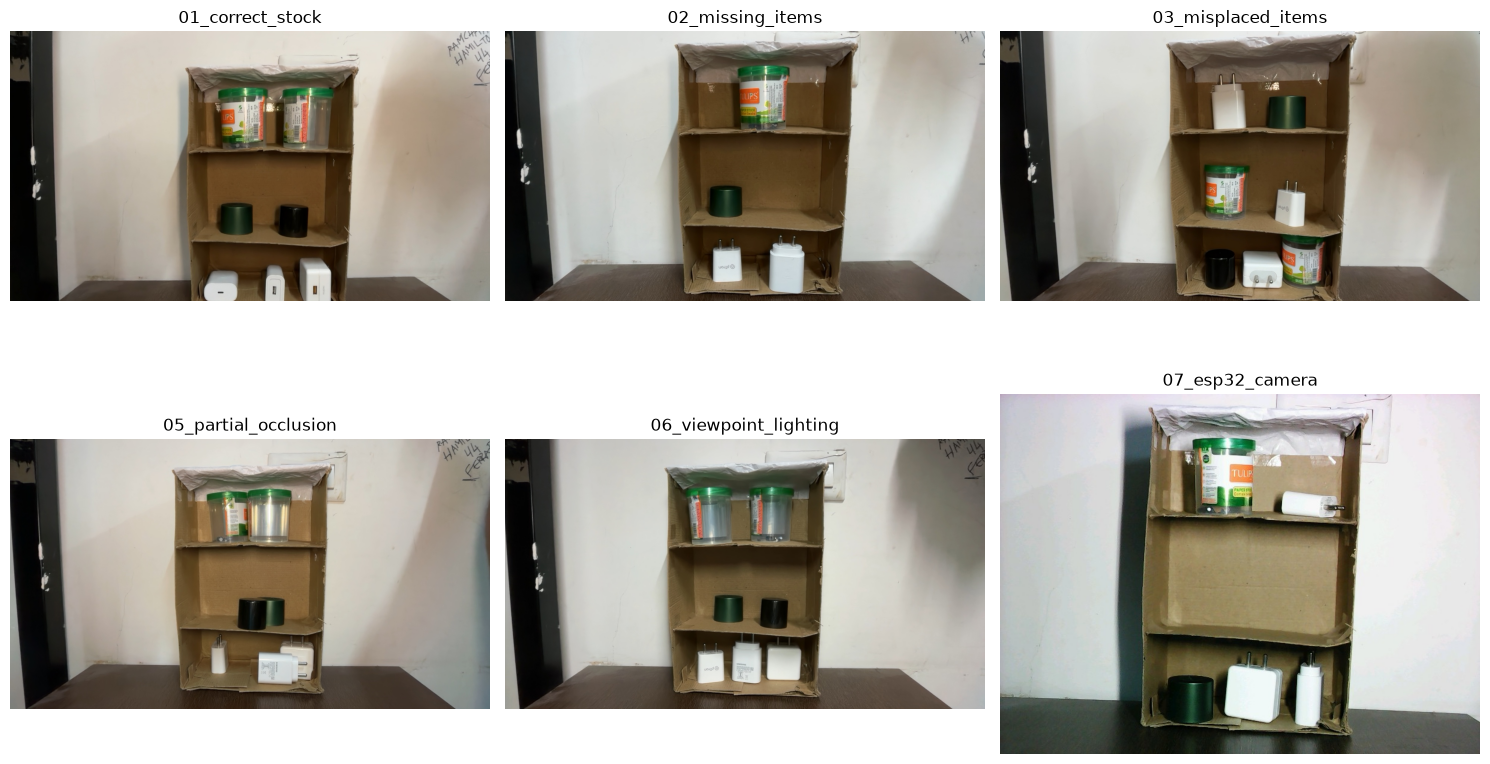

In [4]:
folders = [
    f for f in sorted(RAW.iterdir())
    if f.is_dir() and not f.name.startswith(".")
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, folder in zip(axes.flat, folders):
    imgs = list(folder.glob("*.jpg"))
    img = Image.open(random.choice(imgs))
    
    ax.imshow(img)
    ax.set_title(folder.name)
    ax.axis("off")

plt.tight_layout()

In [9]:
CROPPED = RAW.parent / "cropped"
CROPPED.mkdir(exist_ok=True)

PHONE_CROP = (400, 0, 1000, 720)
ESP_CROP = (180, 0, 620, 600)

for folder in folders:
    out_folder = CROPPED / folder.name
    out_folder.mkdir(parents=True, exist_ok=True)

    for img_path in folder.glob("*.jpg"):
        img = Image.open(img_path)

        if img.size == (1280, 720):
            img = img.crop(PHONE_CROP)

        elif img.size == (800, 600):
            img = img.crop(ESP_CROP)

        img.save(out_folder / img_path.name, quality=95)

print("Done.")

Done.


## Inspecting annotation done with RoboFlow
0: cap;
1: charger_brick;
2: earbud_container;

## YOLOv8 Model Train/Test

In [11]:
from pathlib import Path
import yaml
import torch
import ultralytics

DATASET = Path(r"D:\Portfolio Projects\warehouse_inspector\dataset")
DATA_YAML = DATASET / "data.yaml"

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDataset:", DATASET)
print("YAML:", DATA_YAML)

Ultralytics: 8.4.171
PyTorch: 2.5.1+cu121
CUDA: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU

Dataset: D:\Portfolio Projects\warehouse_inspector\dataset
YAML: D:\Portfolio Projects\warehouse_inspector\dataset\data.yaml


In [12]:
for split in ["train", "valid", "test"]:
    img_dir = DATASET / split / "images"
    lbl_dir = DATASET / split / "labels"

    images = list(img_dir.glob("*"))
    labels = list(lbl_dir.glob("*.txt"))

    print(f"{split:>5}: {len(images)} images | {len(labels)} labels")

train: 211 images | 211 labels
valid: 45 images | 45 labels
 test: 46 images | 46 labels


In [13]:
with open(DATA_YAML, "r") as f:
    config = yaml.safe_load(f)

config

{'train': '../train/images',
 'val': '../valid/images',
 'test': '../test/images',
 'nc': 3,
 'names': ['0', '1', '2'],
 'roboflow': {'workspace': 'vignesh-jaisankar',
  'project': 'warehouse-inspector',
  'version': 4,
  'license': 'Private',
  'url': 'https://app.roboflow.com/vignesh-jaisankar/warehouse-inspector/4'}}

In [14]:
from collections import Counter

class_counts = Counter()

for split in ["train", "valid", "test"]:
    label_dir = DATASET / split / "labels"

    for label_file in label_dir.glob("*.txt"):
        for line in label_file.read_text().splitlines():
            if line.strip():
                class_id = int(line.split()[0])
                class_counts[class_id] += 1

print("Class distribution:")
for cls, count in sorted(class_counts.items()):
    print(f"{cls}: {count}")

Class distribution:
0: 564
1: 858
2: 564


In [15]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")

results = model.train(
    data=str(DATA_YAML),
    epochs=100,
    imgsz=640,
    batch=8,
    device=0,
    patience=20,

    project=r"D:\Portfolio Projects\warehouse_inspector\runs",
    name="final_yolo26n_v1",
    exist_ok=True
)

New https://pypi.org/project/ultralytics/8.4.172 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.171  Python-3.11.9 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Portfolio Projects\warehouse_inspector\dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det

In [16]:
best_model = YOLO(
    r"D:\Portfolio Projects\warehouse_inspector\runs\final_yolo26n_v1\weights\best.pt"
)

test_results = best_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=8,
    device=0
)

Ultralytics 8.4.171  Python-3.11.9 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
YOLO26n summary (fused): 120 layers, 2,375,421 parameters, 0 gradients, 5.3 GFLOPs
WARNING val: Slow image access detected (ping: 0.10.1 ms, read: 5.91.8 MB/s, size: 45.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\Portfolio Projects\warehouse_inspector\dataset\test\labels... 46 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 46/46 751.6it/s 0.1s
val: New cache created: D:\Portfolio Projects\warehouse_inspector\dataset\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.1it/s 5.3s0.2s0
                   all         46        304      0.997      0.993      0.995      0.989
                     0         46         86      0.996          1      0.995      0.991
                     1 

In [17]:
best_model.predict(
    source=r"D:\Portfolio Projects\warehouse_inspector\cropped\07_esp32_camera",
    conf=0.5,
    imgsz=640,
    save=True,
    project=r"D:\Portfolio Projects\warehouse_inspector\runs",
    name="esp32_predictions",
    exist_ok=True
)


image 1/50 D:\Portfolio Projects\warehouse_inspector\cropped\07_esp32_camera\07_esp32_camera_001.jpg: 640x480 2 0s, 3 1s, 2 2s, 50.4ms
image 2/50 D:\Portfolio Projects\warehouse_inspector\cropped\07_esp32_camera\07_esp32_camera_002.jpg: 640x480 2 0s, 3 1s, 2 2s, 48.5ms
image 3/50 D:\Portfolio Projects\warehouse_inspector\cropped\07_esp32_camera\07_esp32_camera_003.jpg: 640x480 2 0s, 3 1s, 2 2s, 47.2ms
image 4/50 D:\Portfolio Projects\warehouse_inspector\cropped\07_esp32_camera\07_esp32_camera_004.jpg: 640x480 2 0s, 3 1s, 2 2s, 46.0ms
image 5/50 D:\Portfolio Projects\warehouse_inspector\cropped\07_esp32_camera\07_esp32_camera_005.jpg: 640x480 2 0s, 3 1s, 2 2s, 46.4ms
image 6/50 D:\Portfolio Projects\warehouse_inspector\cropped\07_esp32_camera\07_esp32_camera_006.jpg: 640x480 2 0s, 3 1s, 2 2s, 46.2ms
image 7/50 D:\Portfolio Projects\warehouse_inspector\cropped\07_esp32_camera\07_esp32_camera_007.jpg: 640x480 2 0s, 4 1s, 2 2s, 31.4ms
image 8/50 D:\Portfolio Projects\warehouse_inspector\c

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: '0', 1: '1', 2: '2'}
 obb: None
 orig_img: array([[[221, 211, 224],
         [221, 211, 224],
         [224, 211, 225],
         ...,
         [245, 234, 242],
         [245, 234, 242],
         [249, 238, 246]],
 
        [[221, 211, 224],
         [221, 211, 224],
         [223, 210, 224],
         ...,
         [237, 226, 234],
         [238, 227, 235],
         [237, 226, 234]],
 
        [[222, 209, 223],
         [223, 210, 224],
         [223, 210, 224],
         ...,
         [232, 220, 226],
         [237, 225, 231],
         [238, 226, 232]],
 
        ...,
 
        [[ 49,  58,  55],
         [ 47,  56,  53],
         [ 45,  54,  51],
         ...,
         [ 91,  98,  93],
         [ 94, 101,  98],
         [ 93, 100,  97]],
 
        [[ 44,  56,  50],
         [ 43,  55,  49],
         [ 43,  52,  49],
        